In [141]:
import pandas as pd
import numpy as np

DATA DESCRIPTION
```
file name -> Columns
quater-i.csv -> ['order_id', 'quantity', 'item_id', 'choice_description_id' 'item_price']
items.csv -> ['item_id', 'item_name']
```
Dataset Link - https://drive.google.com/drive/folders/1Z0kaFybvgFeczeUj4dldUnhTdloLqLsL?usp=share_link

In [142]:
# import like this
items_path = r"D:\Coding Language\Python\DataSet\Task20\items.csv"
q1_path = r"D:\Coding Language\Python\DataSet\Task20\quarter-1.csv"
q2_path = r"D:\Coding Language\Python\DataSet\Task20\quarter-2.csv"
q3_path = r"D:\Coding Language\Python\DataSet\Task20\quarter-3.csv"


q1= pd.read_csv(q1_path)
q2 = pd.read_csv(q2_path)
q3 = pd.read_csv(q3_path)
items = pd.read_csv(items_path)

###`Q:1-5`
1. You are given three quater files, your job is to append these three files and make a single dataframe.
2. Have a index as Q-1 Q-2 Q-3 for respective quater files in the dataframe
3. Your are given a file items.csv which has item_id and item_name. Find out most sold items in each quarter.
4. Find out items which has made most revenue in each quarter.
5. Find out avg order price of each quarter.

***Note: item_price is given as str with $ sign, in earlier task you have converted this to rupees, here too first convert item_price field in rupees.***

In [143]:
# code here
# 1 and 2
df1=pd.concat([q1,q2,q3],keys=['q1','q2','q3'])
df1.reset_index(inplace=True)
df1['item_price']=df1['item_price'].str.strip('$').astype('float')*95.84
df1['total_price']=df1['item_price']*df1['quantity']
# pd.concat([df1,items],keys='item_id')
merged=df1.merge(items,on='item_id')
merged.rename(columns={"level_0":"quarter"},inplace=True)
# 3
merged.groupby(['quarter','item_name'],as_index=False)['quantity'].sum().sort_values('quantity',ascending=False).drop_duplicates(subset='quarter',keep='first')
# 4
merged.groupby(['quarter','item_name'],as_index=False)['total_price'].sum().sort_values('total_price',ascending=False).drop_duplicates(subset='quarter',keep='first')
# 5
merged.groupby(['quarter','order_id'],as_index=False)['total_price'].sum().groupby('quarter')['total_price'].mean()
merged




,quarter,level_1,order_id,quantity,item_id,choice_description_id,item_price,total_price,item_name
0,q1,0,1,1,1,1,324.8976,324.8976,Izze
1,q1,1,1,1,2,2,324.8976,324.8976,Nantucket Nectar
2,q1,2,2,2,4,3,1627.3632,3254.7264,Chicken Bowl
3,q1,3,4,1,7,6,886.5200,886.52,Steak Soft Tacos
4,q1,4,6,1,9,8,838.6000,838.6,Chicken Crispy Tacos
...,...,...,...,...,...,...,...,...,...
4617,q2,2342,1829,1,23,92,1078.2000,1078.2,Veggie Burrito
4618,q2,2343,1830,1,23,1043,1078.2000,1078.2,Veggie Burrito
4619,q2,2344,1832,1,10,116,838.6000,838.6,Chicken Soft Tacos
4620,q2,2345,1832,1,8,0,426.4880,426.488,Chips and Guacamole


###`Q-6` From the IPL wala dataset you have to find the Purple cap holder each season.

*Note: Bowler with most no wickets in a season gets purple cap. If more than one bowler have same no of wickets in the season, one with least ecomnomy among them is purple cap holder.*

Bowler's Economy = runs-conceded per six balls

In [144]:
# code here
delivery = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\IPL_Ball_by_Ball_2008_2022.csv")
matches = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\IPL_Matches_2008_2022.csv")
delivery
merged = matches.merge(delivery,on='ID')
merged['WicketTaken'] = merged['kind'].apply(lambda x: 1 if x in ['caught','caught and bowled','bowled', 'stumped','lbw', 'hit wicket'] else 0)
merged['bowlerRun']=merged['extra_type'].apply(lambda x: 0 if x in ['legbyes','byes'] else 1) * merged['total_run']
merged['legalBall']=merged['extra_type'].apply(lambda x: 0 if x in ['wides','noballs'] else 1)

print(merged.columns)
val=merged.groupby(['Season','bowler'])[['WicketTaken','bowlerRun','legalBall']].agg({'WicketTaken':'sum','bowlerRun':'sum','legalBall':'sum'})
val['BowlerEco']=val['bowlerRun']/val['legalBall']*6
val.sort_values(by=['WicketTaken','BowlerEco'],ascending=[False,True],inplace=True)
val = val.reset_index()
val.drop_duplicates(subset=['Season'],keep='first',inplace=True)
val.sort_values(by='Season')

Index(['ID', 'City', 'Date', 'Season', 'MatchNumber', 'Team1', 'Team2',
       'Venue', 'TossWinner', 'TossDecision', 'SuperOver', 'WinningTeam',
       'WonBy', 'Margin', 'method', 'Player_of_Match', 'Team1Players',
       'Team2Players', 'Umpire1', 'Umpire2', 'innings', 'overs', 'ballnumber',
       'batter', 'bowler', 'non-striker', 'extra_type', 'batsman_run',
       'extras_run', 'total_run', 'non_boundary', 'isWicketDelivery',
       'player_out', 'kind', 'fielders_involved', 'BattingTeam', 'WicketTaken',
       'bowlerRun', 'legalBall'],
      dtype='object')


,Season,bowler,WicketTaken,bowlerRun,legalBall,BowlerEco
29,2007/08,Sohail Tanvir,22,266,247,6.461538
21,2009,RP Singh,23,417,358,6.988827
40,2009/10,PP Ojha,21,429,353,7.291785
4,2011,SL Malinga,28,375,378,5.952381
12,2012,M Morkel,25,453,378,7.190476
0,2013,DJ Bravo,32,497,375,7.952000
24,2014,MM Sharma,23,452,323,8.396285
11,2015,DJ Bravo,26,426,314,8.140127
22,2016,B Kumar,23,490,396,7.424242
8,2017,B Kumar,26,369,314,7.050955


###`Q-7:` Best bowler in death overs.
*Note: Have taken most no of wickets in case of tie with least economy*

Death Overs - [16-20]

In [145]:
# code here
death = delivery[delivery['overs']>=16]
death['WicketTaken'] = death['kind'].apply(lambda x: 1 if x in ['caught','caught and bowled','bowled', 'stumped','lbw', 'hit wicket'] else 0)
death['bowlerRun']=death['extra_type'].apply(lambda x: 0 if x in ['legbyes','byes'] else 1) * death['total_run']
death['legalBall']=death['extra_type'].apply(lambda x: 0 if x in ['wides','noballs'] else 1)
# # death.groupby(['ID','bowler'])
data=death.groupby(['bowler'])[['WicketTaken','bowlerRun','legalBall']].sum()
data['Eco']=data['bowlerRun']/data['legalBall']*6
data.sort_values(by=['WicketTaken','Eco'],ascending=[False,True],inplace=True)
data.head(1)

C:\Users\prana\AppData\Local\Temp\ipykernel_5148\3229193455.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  death['WicketTaken'] = death['kind'].apply(lambda x: 1 if x in ['caught','caught and bowled','bowled', 'stumped','lbw', 'hit wicket'] else 0)
C:\Users\prana\AppData\Local\Temp\ipykernel_5148\3229193455.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  death['bowlerRun']=death['extra_type'].apply(lambda x: 0 if x in ['legbyes','byes'] else 1) * death['total_run']
C:\Users\prana\AppData\Local\Temp

,WicketTaken,bowlerRun,legalBall,Eco
bowler,,,,
DJ Bravo,102,1810,1115,9.73991


###`Q-8` Batsman record season wise

Make a function which takes a input `batsman_name` and it returns a dataframe.
Columns of the data frame are - `['Season','Innings', 'TotalRuns', 'Avg', 'HighestScore','StrikeRate']`.
* In result make `Season` column as index.

* Avg - total_runs/ no of time got out. - player_out column will help.
* StrikeRate -(total_runs/ balls faced) * 100- wides are not included in batsman ball faced counts. No balls are included. -> Extra_type column will help
* Batsman Can score runs on No Balls.
* Batsman can get out on No Ball or Wides. And even while being on non-striker. Keep these things in mind before masking.

In [146]:
# code here
df=matches.merge(delivery,on='ID')

def list(batter,df):
    df=df[df['batter']==batter]
    df['legalBall']=df['extra_type'].apply(lambda x: 0 if x in ['wides'] else 1)
    df['BatsManOut'] = df['kind'].apply(lambda x: 1 if x in ['caught','caught and bowled','bowled', 'stumped','lbw', 'hit wicket','runout'] else 0)
    data=df.groupby(['Season'])[['ID','total_run','BatsManOut','legalBall']].agg({'ID':'nunique','total_run':'sum','BatsManOut':'sum','legalBall':'sum'})
    # df.groupby('Season')['ID'].count()
    data.rename(columns={'ID':'innings'},inplace=True)
    # data['A Ashish Reddy']
    data['AVG']=data['total_run']/data['BatsManOut']
    data['strikeRate']=data['total_run']/data['legalBall']*100
    max=df.groupby(['Season','ID',])['batsman_run'].sum().reset_index().sort_values(by='batsman_run',ascending=False)
    max.drop_duplicates('Season',inplace=True)
    data=data.merge(max,on='Season')
    data.drop(columns=['BatsManOut','legalBall','ID'],inplace=True)
    data.rename(columns={'batsman_run':'max_run'},inplace=True)
    data.set_index('Season',inplace=True)
    return data

list('V Kohli',df)

C:\Users\prana\AppData\Local\Temp\ipykernel_5148\3454068683.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['legalBall']=df['extra_type'].apply(lambda x: 0 if x in ['wides'] else 1)
C:\Users\prana\AppData\Local\Temp\ipykernel_5148\3454068683.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['BatsManOut'] = df['kind'].apply(lambda x: 1 if x in ['caught','caught and bowled','bowled', 'stumped','lbw', 'hit wicket','runout'] else 0)


,innings,total_run,AVG,strikeRate,max_run
Season,,,,,
2007/08,12,187,17.000000,119.108280,38
2009,13,258,23.454545,117.808219,50
2009/10,13,320,32.000000,150.943396,58
2011,16,584,48.666667,126.956522,71
2012,15,375,31.250000,115.030675,73
2013,16,660,55.000000,143.790850,99
2014,14,373,31.083333,126.870748,73
2015,16,519,51.900000,134.455959,82
2016,16,998,83.166667,155.937500,113


###`Q-9` Using both dataset, make a dataframe as described below

Data Frame columns-> `['PlayerOfThematch', 'BattingFigure', 'BowlingFigure']`

* BattingFigure->`<runs>/<balls>`
* BowlingFigure->`<wicket>/<runs-conceded>`

DataFrame should have one record for each match.

Say 'V Kohli' got POM award then in dataset include his batting figure of that match. Say he scored 112runs in 76 balls. And he hasn't bowled so Bowling Figure will be NaN
```
PlayerOfThematch BattingFigure BowlingFigure
V Kohli          112/76         nan  

```


In [ ]:
# code here



## **Questions Based on Iris Dataset**

- **Sepal All:** https://docs.google.com/spreadsheets/d/e/2PACX-1vT58ekmHTwptX7Bs4QOy6YByA1HMvYTACeeIjrKhHE0Pg1K_3egewHMKMh02zN9D5-yHVXfvuaa3s5u/pub?gid=2028782809&single=true&output=csv
    - **Unnamed: 0:** Unused column. This column is created when creating this sub-dataset.
    - **Id:** Id of the records.
    - **SepalLengthCm:** Sepal length of flowers in cm
    - **SepalWidthCm:** Sepal width of flowers in cm

- **Petal All:** https://docs.google.com/spreadsheets/d/e/2PACX-1vQinLXShrOz4ExNaW1bSQVuvbbhIzJW7G0kkkD2SvqSD6STjLrQQiftgI7BGe10sBZi0CNr2_sJpQAz/pub?gid=1580010789&single=true&output=csv
    - **Unnamed: 0:** Unused column. This column is created when creating this sub-dataset.
    - **Id:** Id of the records.
    - **PetalLengthCm:** Petal length of flowers in cm
    - **PetalWidthCm:** Petal width of flowers in cm

- **Iris Virginica:** https://docs.google.com/spreadsheets/d/e/2PACX-1vSK39MwduGPHYNgw5yViezoLYCVDKMCWIHzjnt3GZNaxHPFOQLr2q6no_tyqTsOk-VfXleslfGVe9eJ/pub?gid=314231613&single=true&output=csv
    - **Unnamed: 0:** Unused column. This column is created when creating the sub-dataset.
    - **Id:** Id of the records.
    - **Species:** Name of this species.

- **Iris Versicolor:** https://docs.google.com/spreadsheets/d/e/2PACX-1vTcSFgLnabqIrgIc5WlwvnbbvyyJsgZjR-0E0-4TR-5aHgv_0EP6yNWglkkls3AXM2qHCR5VYzWCoTM/pub?gid=715607857&single=true&output=csv
    - **Unnamed: 0:** Unused column. This column is created when creating the sub-dataset.
    - **Id:** Id of the records.
    - **Species:** Name of this species.

- **Iris Setosa:** https://docs.google.com/spreadsheets/d/e/2PACX-1vSjqJpdgy2X_oDUUqQ0sSaFKqnnf8MYU4KgJSYgHaHmq0Wb1weMOsJXh-rICHmkLcaTkOwzMYLeh959/pub?gid=2003684803&single=true&output=csv
    - **Unnamed 0:** Unused column. This column is created when creating the sub-dataset.
    - **Id:** Id of the records.
    - **Species:** Name of this species.

In [188]:
import pandas as pd
sepal_all = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\sepal_all - sepal_all.csv")
petal_all = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\petal_all - petal_all.csv")

virginica = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\virginica - virginica.csv")
versicolor = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\versicolor - versicolor.csv")
setosa = pd.read_csv(r"D:\Coding Language\Python\DataSet\Task20\setosa - setosa.csv")
petal_all

,Unnamed: 0,Id,PetalLengthCm,PetalWidthCm
0,0,1,1.4,0.2
1,1,2,1.4,0.2
2,2,3,1.3,0.2
3,3,4,1.5,0.2
4,4,5,1.4,0.2
...,...,...,...,...
145,145,146,5.2,2.3
146,146,147,5.0,1.9
147,147,148,5.2,2.0
148,148,149,5.4,2.3


### `Q-9:` Plot a bar chart of the average Sepal Length  of Virginica and average Petal length of Setosa flower.

<BarContainer object of 2 artists>

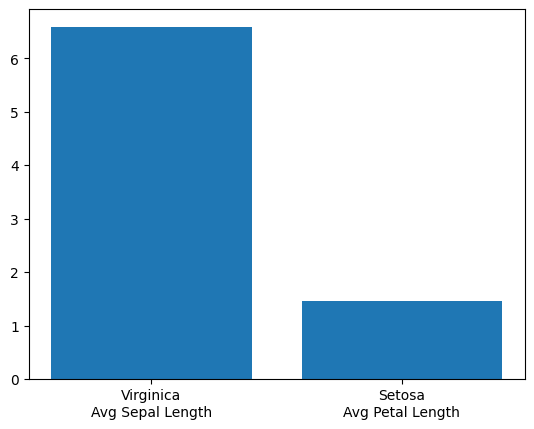

In [189]:
# code here
import matplotlib.pyplot as plt
import seaborn as sns
virginica=virginica.merge(sepal_all,on='Id')['SepalLengthCm'].mean()
setosa=setosa.merge(petal_all,on='Id')['PetalLengthCm'].mean()
plt.bar(    ["Virginica\nAvg Sepal Length", "Setosa\nAvg Petal Length"],
    [virginica,setosa]
)




### `Q-10:` Create the complete dataset by uisng the below datasets:
- virginica
- versicolor
- setosa
- sepal all
- petal all

This dataset should have these below column names in order:
1. Id
2. Species
3. SepalLengthCm
4. SepalWidthCm
5. PetalLengthCm
6. PetalWidthCm

Also, the dataset should be shuffled means the `Id` column should not be in increasing or decreasing order. So, make a dataset which has the shuffled Id column. You can use `DataFrame.sample()` method to shuffle.

In [ ]:
# code here

### `Q-11:` Find out the maximum and minimum sepal width and petal width of Setosa and Versicolor. To do this:
- First create a dataset with merging the required datasets
- After that, use `groupby` to create groups based on the "Species" column.
- Then find out which are asked in this question.


The output should be like this:
```bash
Minimum Sepal width of Setosa is 2.3
Maximum Sepal width of Setosa is 4.4

**************************************************

Minimum Sepal width of Versicolor is 2.0
Maximum Sepal width of Versicolor is 3.4

**************************************************
```

In [ ]:
# code here